In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import iqr as count_iqr
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [3]:
df = pd.read_excel("ДанныеКластеризация.xlsx",  sheet_name = "2003").set_index("regions")
# df = df[~df["regions"].isin(["Чукотский автономный округ", "Республика Адыгея", "Республика Тыва"])].set_index("regions")

In [4]:
df_with_clusters_not_scaled = df.copy()

In [5]:
scaler = StandardScaler()
scaler.fit(df)
df_scaled = scaler.transform(df)

for i in df.columns:
    df[i] = df_scaled[:, 0] 

df.head()

,x1,x2,x3,x4
regions,,,,
Белгородская область,-0.548678,-0.548678,-0.548678,-0.548678
Брянская область,-0.488368,-0.488368,-0.488368,-0.488368
Владимирская область,0.396186,0.396186,0.396186,0.396186
Воронежская область,-0.789920,-0.789920,-0.789920,-0.789920
Ивановская область,-0.287333,-0.287333,-0.287333,-0.287333


In [6]:
df_with_clusters_scaled = df.copy()

In [7]:
agg_cluster = AgglomerativeClustering(n_clusters=6, linkage='ward')
df_with_clusters_not_scaled["clusters"] = agg_cluster.fit_predict(df)
df_with_clusters_scaled["clusters"] = agg_cluster.fit_predict(df)

In [8]:
df_with_clusters_not_scaled.groupby(by = ["clusters"]).count() 

,x1,x2,x3,x4
clusters,,,,
0,8,8,8,8
1,27,27,27,27
2,17,17,17,17
3,23,23,23,23
4,6,6,6,6
5,1,1,1,1


In [9]:
df_with_clusters_not_scaled[df_with_clusters_not_scaled['clusters'] == 5]

,x1,x2,x3,x4,clusters
regions,,,,,
Республика Ингушетия,40.5,55.8,1.554,83.0,5


<Axes: >

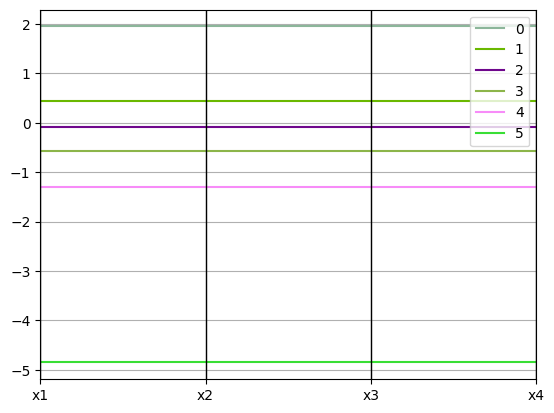

In [10]:
df_with_means = df_with_clusters_scaled.groupby(by = ["clusters"]).mean().reset_index()

pd.plotting.parallel_coordinates(df_with_means, "clusters")

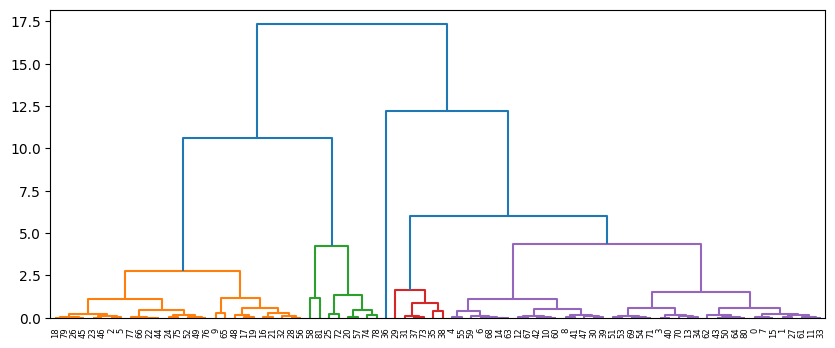

In [11]:
Z = linkage(df, method='ward', metric='euclidean')

fig = plt.figure(figsize=(10, 4))
dn = dendrogram(Z, color_threshold=5, orientation="top")
plt.show()

In [12]:
df_with_clusters_not_scaled.to_excel("clusters.xlsx")